In [4]:
import pandas as pd
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:,.0f}'.format)

In [5]:
df = pd.read_excel(
    "3133.ods",
    sheet_name="3133_Punctuality_(quarterly)",
    header=2,        # row 2 becomes the column names
    skiprows=[0], # remove the first two metadata rows
    engine="odf"
)

In [6]:
df

,Time period,National or Operator,Number of recordedstation stops,Trains arriving within 59 seconds (percentage),Trains arriving within 3 minutes (percentage),Trains arriving within 15 minutes (percentage),Moving annual total number of recordedstation stops,Moving annual average of trains arriving within 59 seconds (percentage),Moving annual average of trains arriving within 3 minutes (percentage),Moving annual average of trains arriving within 15 minutes (percentage)
0,Apr to Jun 2014,Great Britain,"16,529,011",68,88,99,"64,913,801",64,85,99
1,Jul to Sep 2014,Great Britain,"16,793,877",66,86,99,"65,182,538",64,85,99
2,Oct to Dec 2014,Great Britain,"16,185,464",59,81,98,"65,483,661",64,85,99
3,Jan to Mar 2015,Great Britain,"16,263,773",66,86,99,"65,772,125",64,85,99
4,Apr to Jun 2015,Great Britain,"16,658,713",68,87,99,"65,901,826",64,85,99
...,...,...,...,...,...,...,...,...,...,...
1177,Apr to Jun 2024,West Midlands Trains,"1,070,418",66,84,98,"4,197,446",63,82,98
1178,Jul to Sep 2024,West Midlands Trains,"1,128,001",64,82,98,"4,299,407",63,82,98
1179,Oct to Dec 2024,West Midlands Trains,"1,082,045",58,78,98,"4,350,782",63,82,98
1180,Jan to Mar 2025,West Midlands Trains,"1,137,478",70,86,99,"4,417,942",64,83,98


In [7]:
import re

def remove_notes(x):
    if isinstance(x, str):
        return re.sub(r"\s*\[.*?\]", "", x)
    return x

# Apply only to object (string) columns
for col in df.select_dtypes(include="object"):
    df[col] = df[col].map(remove_notes)

df

,Time period,National or Operator,Number of recordedstation stops,Trains arriving within 59 seconds (percentage),Trains arriving within 3 minutes (percentage),Trains arriving within 15 minutes (percentage),Moving annual total number of recordedstation stops,Moving annual average of trains arriving within 59 seconds (percentage),Moving annual average of trains arriving within 3 minutes (percentage),Moving annual average of trains arriving within 15 minutes (percentage)
0,Apr to Jun 2014,Great Britain,"16,529,011",68,88,99,"64,913,801",64,85,99
1,Jul to Sep 2014,Great Britain,"16,793,877",66,86,99,"65,182,538",64,85,99
2,Oct to Dec 2014,Great Britain,"16,185,464",59,81,98,"65,483,661",64,85,99
3,Jan to Mar 2015,Great Britain,"16,263,773",66,86,99,"65,772,125",64,85,99
4,Apr to Jun 2015,Great Britain,"16,658,713",68,87,99,"65,901,826",64,85,99
...,...,...,...,...,...,...,...,...,...,...
1177,Apr to Jun 2024,West Midlands Trains,"1,070,418",66,84,98,"4,197,446",63,82,98
1178,Jul to Sep 2024,West Midlands Trains,"1,128,001",64,82,98,"4,299,407",63,82,98
1179,Oct to Dec 2024,West Midlands Trains,"1,082,045",58,78,98,"4,350,782",63,82,98
1180,Jan to Mar 2025,West Midlands Trains,"1,137,478",70,86,99,"4,417,942",64,83,98


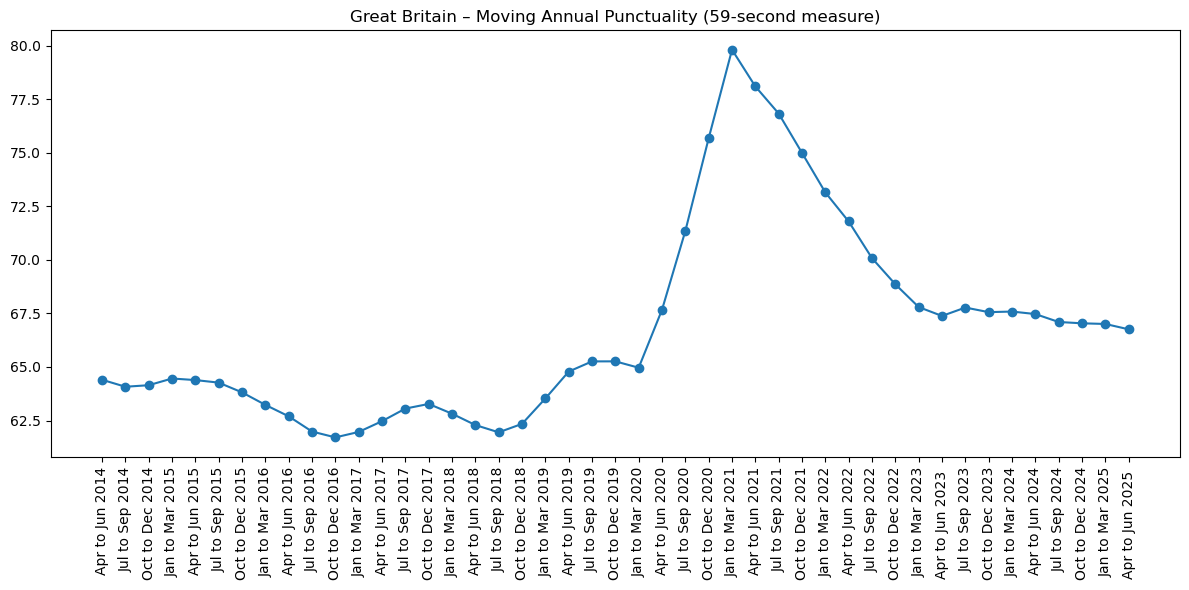

In [8]:
import matplotlib.pyplot as plt
gb = df[df["National or Operator"] == "Great Britain"]

plt.figure(figsize=(12,6))
plt.plot(gb["Time period"], gb["Moving annual average of trains arriving within 59 seconds  (percentage)"], marker="o")

plt.title("Great Britain – Moving Annual Punctuality (59-second measure)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()




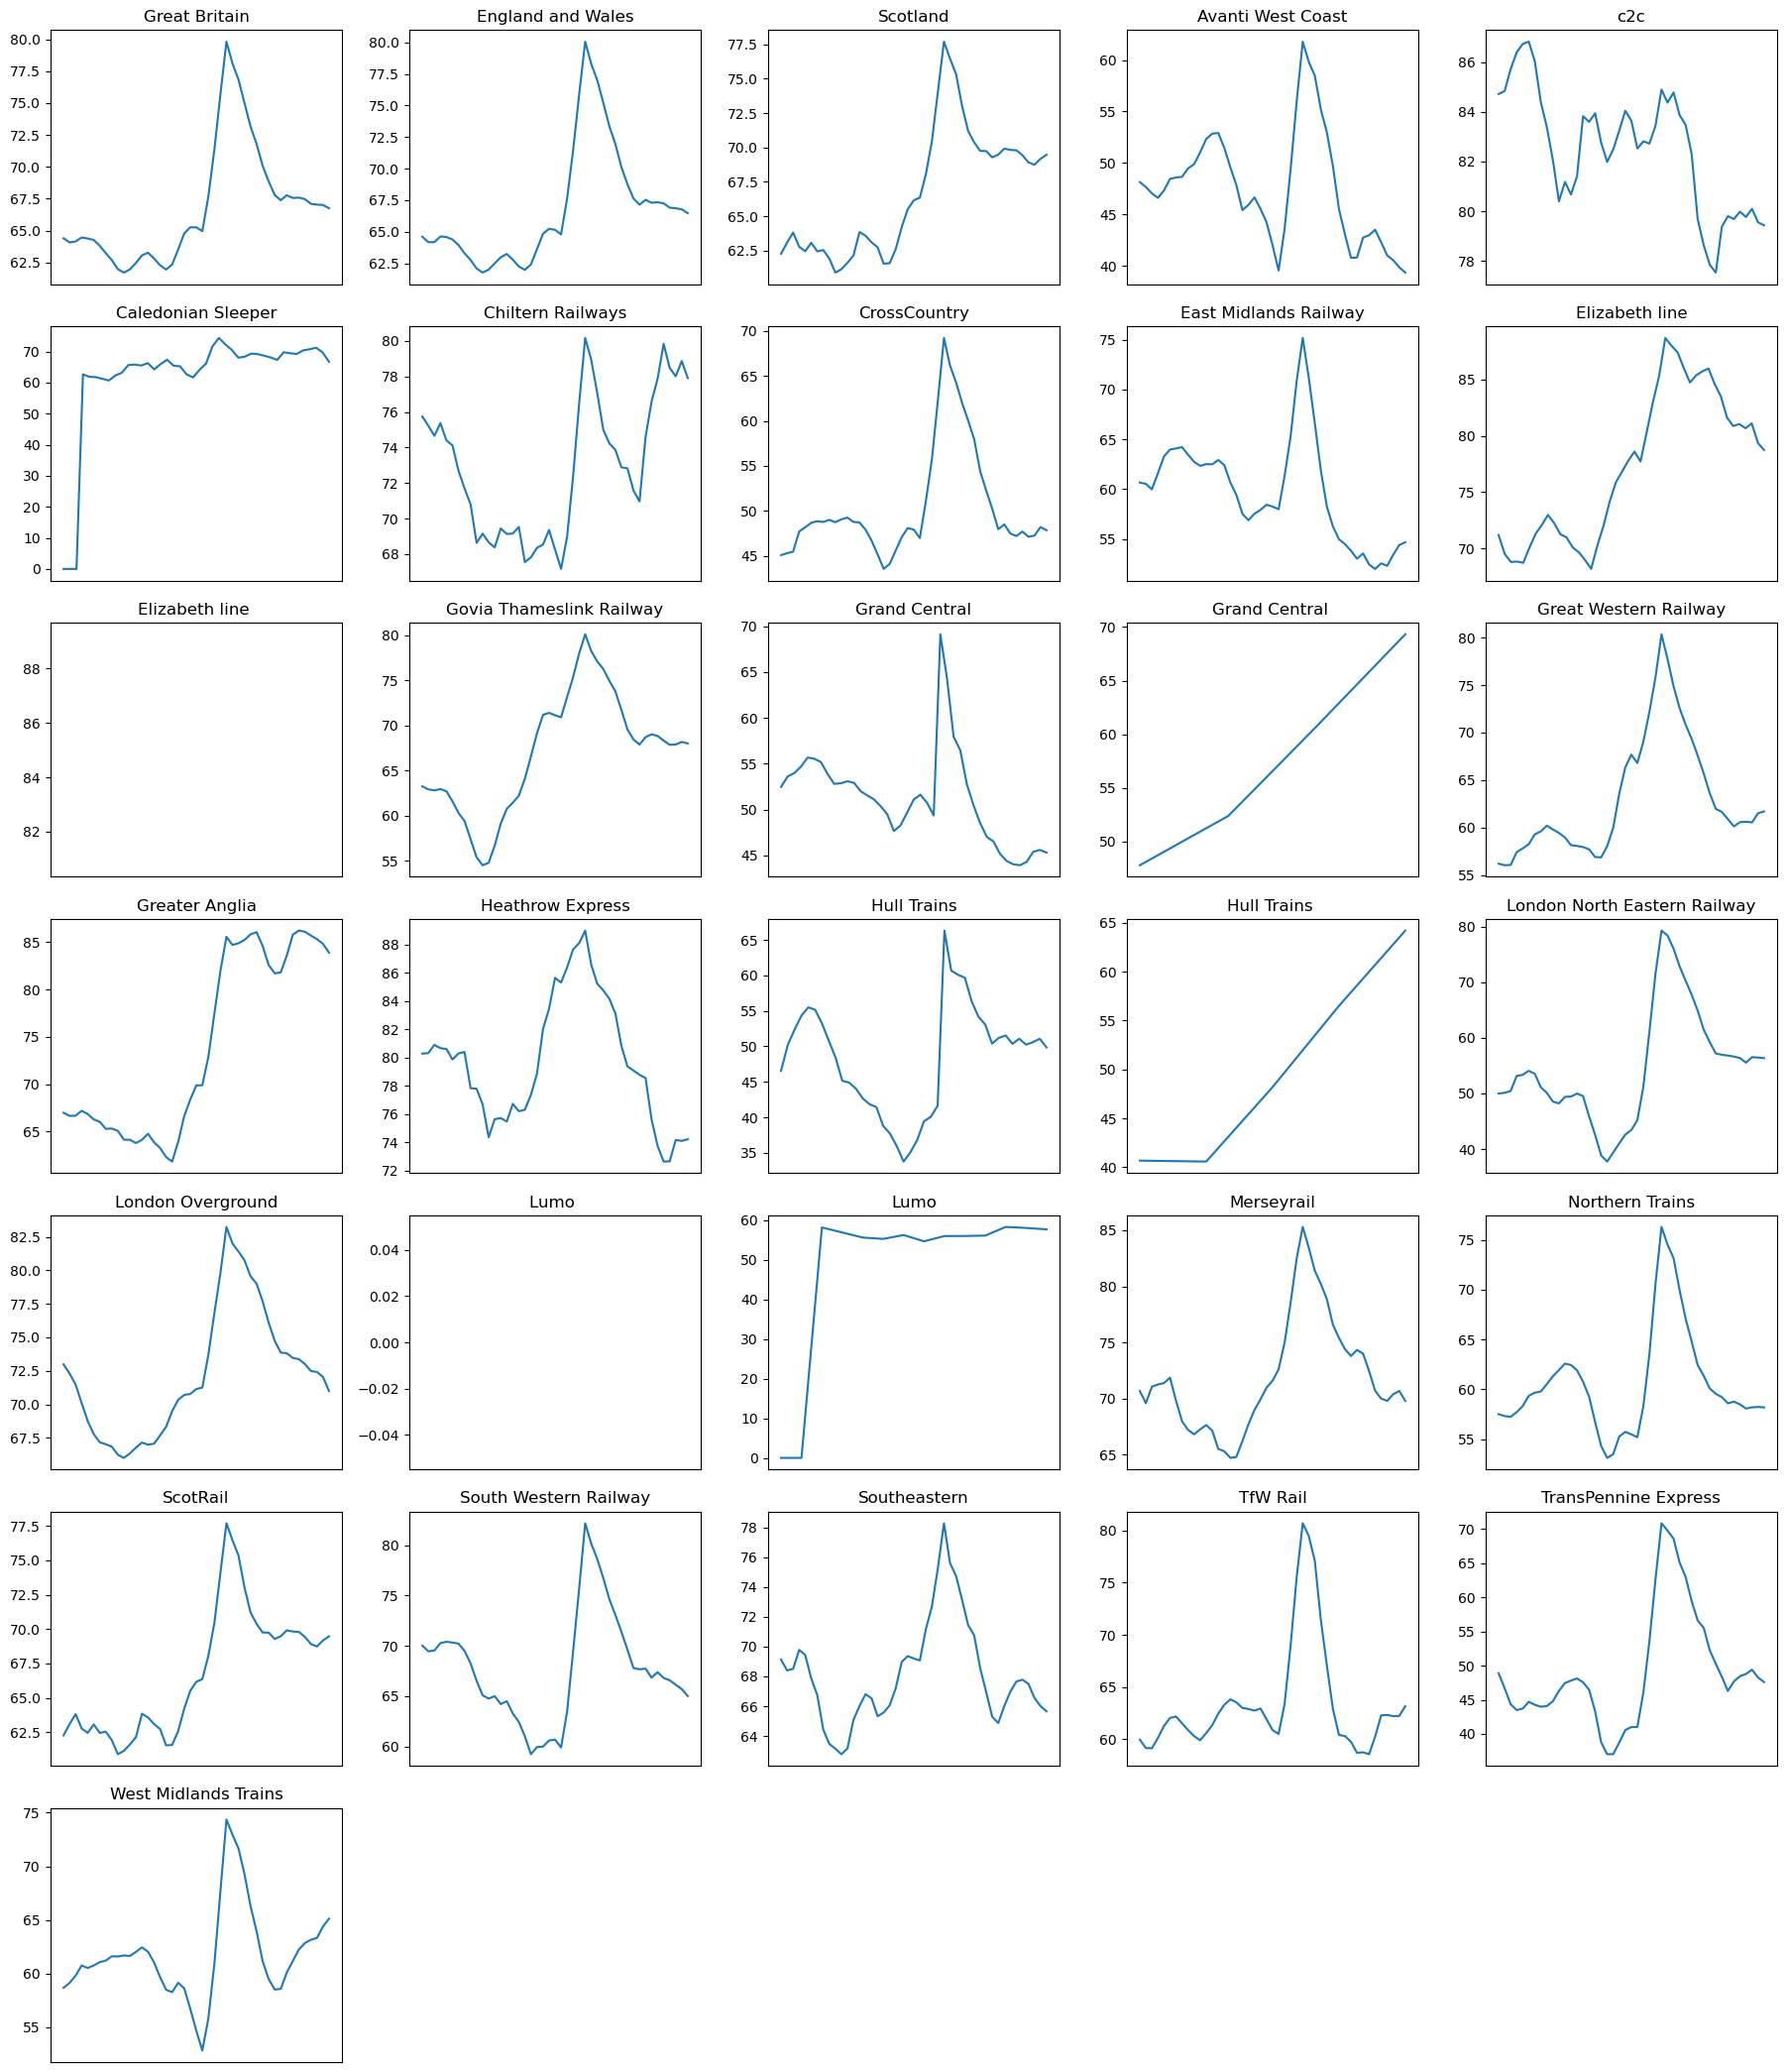

In [9]:
import matplotlib.pyplot as plt

operators = df["National or Operator"].unique()
n = len(operators)

cols = 5
rows = (n + cols - 1) // cols

plt.figure(figsize=(18, rows * 3))

for i, op in enumerate(operators, 1):
    subset = df[df["National or Operator"] == op]
    plt.subplot(rows, cols, i)
    plt.plot(
        subset["Time period"],
        subset["Moving annual average of trains arriving within 59 seconds  (percentage)"]
    )
    plt.title(op)
    plt.xticks([], [])   # hide x-axis labels for readability

plt.tight_layout()
plt.show()

In [10]:
df2 = df = pd.read_excel(
    "3123.ods",
    sheet_name="3123_Cancellations_by_operator",
    header=2,        # row 2 becomes the column names
    skiprows=[0], # remove the first two metadata rows
    engine="odf"
)
df2

,Time period,National or Operator,Number of trains planned,Number of trains part cancelled,Number of trains full cancelled,Cancellations [note 1],"Cancellations by responsibility, infrastructure and network management [r]","Cancellations by responsibility, infrastructure owner external event [r]","Cancellations by responsibility, train operator fault [r]","Cancellations by responsibility, operator external event [r]",Quarterly cancellations (percentage),Moving annual average cancellations (percentage)
0,Apr to Jun 2019,Avanti West Coast,"25,266",247,250,374,115,149,105,4,1,2
1,Apr to Jun 2020,Avanti West Coast,"15,585",117,128,186,55,57,70,4,1,3
2,Apr to Jun 2021,Avanti West Coast,"17,590",273,278,414,145,101,161,7,2,2
3,Apr to Jun 2022,Avanti West Coast,"19,875",461,"1,326","1,556",225,126,"1,175",30,8,5
4,Apr to Jun 2023,Avanti West Coast,"20,226",406,503,706,130,213,334,29,3,8
...,...,...,...,...,...,...,...,...,...,...,...,...
660,Oct to Dec 2020,West Midlands Trains,"94,795","1,520","1,852","2,613",763,503,"1,217",130,3,3
661,Oct to Dec 2021,West Midlands Trains,"100,027","2,819","4,380","5,790",887,588,"4,044",222,6,4
662,Oct to Dec 2022,West Midlands Trains,"85,410","2,520","3,065","4,325","1,066",707,"2,082",353,5,5
663,Oct to Dec 2023,West Midlands Trains,"93,457","2,786","3,885","5,278",877,"1,192","2,925",267,6,4


In [11]:
df2.columns

Index(['Time period', 'National or Operator', 'Number of trains planned ', 'Number of trains part cancelled', 'Number of trains full cancelled', 'Cancellations [note 1]', 'Cancellations by responsibility, infrastructure and network management [r]', ' Cancellations by responsibility, infrastructure owner external event [r]', 'Cancellations by responsibility, train operator fault [r]', 'Cancellations by responsibility, operator external event [r]', 'Quarterly cancellations (percentage) ', 'Moving annual average cancellations (percentage)'], dtype='object')

In [12]:
df2 = df2.apply(lambda col: col.map(remove_notes))
df2

,Time period,National or Operator,Number of trains planned,Number of trains part cancelled,Number of trains full cancelled,Cancellations [note 1],"Cancellations by responsibility, infrastructure and network management [r]","Cancellations by responsibility, infrastructure owner external event [r]","Cancellations by responsibility, train operator fault [r]","Cancellations by responsibility, operator external event [r]",Quarterly cancellations (percentage),Moving annual average cancellations (percentage)
0,Apr to Jun 2019,Avanti West Coast,"25,266",247,250,374,115,149,105,4,1,2
1,Apr to Jun 2020,Avanti West Coast,"15,585",117,128,186,55,57,70,4,1,3
2,Apr to Jun 2021,Avanti West Coast,"17,590",273,278,414,145,101,161,7,2,2
3,Apr to Jun 2022,Avanti West Coast,"19,875",461,"1,326","1,556",225,126,"1,175",30,8,5
4,Apr to Jun 2023,Avanti West Coast,"20,226",406,503,706,130,213,334,29,3,8
...,...,...,...,...,...,...,...,...,...,...,...,...
660,Oct to Dec 2020,West Midlands Trains,"94,795","1,520","1,852","2,613",763,503,"1,217",130,3,3
661,Oct to Dec 2021,West Midlands Trains,"100,027","2,819","4,380","5,790",887,588,"4,044",222,6,4
662,Oct to Dec 2022,West Midlands Trains,"85,410","2,520","3,065","4,325","1,066",707,"2,082",353,5,5
663,Oct to Dec 2023,West Midlands Trains,"93,457","2,786","3,885","5,278",877,"1,192","2,925",267,6,4


In [13]:
df2["National or Operator"].unique()

array(['Avanti West Coast', 'c2c', 'Caledonian Sleeper',
       'Chiltern Railways', 'CrossCountry', 'East Midlands Railway',
       'Elizabeth line', 'England and Wales', 'Govia Thameslink Railway',
       'Grand Central', 'Great Britain', 'Great Western Railway',
       'Greater Anglia', 'Heathrow Express', 'Hull Trains',
       'London North Eastern Railway', 'London Overground', 'Lumo',
       'Merseyrail', 'Northern Trains', 'Scotland', 'ScotRail',
       'South Western Railway', 'Southeastern', 'TfW Rail',
       'TransPennine Express', 'West Midlands Trains'], dtype=object)

In [14]:
df2.columns = df2.columns.str.strip()

In [15]:
summary = df2.groupby("National or Operator", as_index=False).agg({
    "Number of trains planned": "sum",
    "Cancellations [note 1]": "sum",
    "Cancellations by responsibility, infrastructure and network management [r]": "sum",
    "Cancellations by responsibility, infrastructure owner external event [r]": "sum",
    "Cancellations by responsibility, train operator fault [r]": "sum",
    "Cancellations by responsibility, operator external event [r]": "sum"
})

summary = summary.rename(columns={
    "National or Operator": "Train operator",
    "Number of trains planned": "Total trains planned",
    "Cancellations [note 1]": "Total cancellations",
    "Cancellations by responsibility, infrastructure and network management [r]":
        "Infra & network management",
    "Cancellations by responsibility, infrastructure owner external event [r]":
        "Infra external events",
    "Cancellations by responsibility, train operator fault [r]":
        "Operator fault",
    "Cancellations by responsibility, operator external event [r]":
        "Operator external event"
})

summary

,Train operator,Total trains planned,Total cancellations,Infra & network management,Infra external events,Operator fault,Operator external event
0,Avanti West Coast,"519,282","26,118","6,122","5,284","14,150",538
1,Caledonian Sleeper,"11,668",376,57,136,178,3
2,Chiltern Railways,"689,112","12,606","2,989","2,779","6,419",412
3,CrossCountry,"504,319","26,112","6,134","5,224","14,134",620
4,East Midlands Railway,"979,258","26,827","6,391","6,115","13,422",853
5,Elizabeth line,"1,590,990","47,134","18,178","7,214","20,204","1,499"
6,England and Wales,"39,375,839","1,391,092","374,409","257,537","700,787","55,225"
7,Govia Thameslink Railway,"6,971,943","340,985","96,303","56,030","174,253","13,414"
8,Grand Central,"34,542","1,482",308,268,879,27
9,Great Britain,"43,607,052","1,493,261","397,504","284,847","747,321","60,378"


In [16]:
df.columns = df.columns.str.strip()

In [17]:
MariaData = pd.read_excel("MariaData.xlsx")

In [18]:
MariaData

,time period,train operating company name,NR on TOC External,NR on TOC Network Management Other,NR on TOC Non Track Assets,NR on TOC Severe Weather,NR on TOC Track,TOC on Self Fleet,TOC on Self Operations,TOC on Self Stations,TOC on Self TOC Other,TOC on Self Traincrew,TOC on TOC Fleet,TOC on TOC Operations,TOC on TOC Stations,TOC on TOC TOC Other,TOC on TOC Traincrew
0,Apr 2019 to Mar 2020 (Period 01),Avanti West Coast,"6,458","9,380","4,894",432,"5,191","4,384",142,892,"1,434",386,"3,595",348,364,865,714
1,Apr 2019 to Mar 2020 (Period 02),Avanti West Coast,"13,273","5,789","6,547","1,424","5,990","2,124",196,568,"1,234",743,"4,944",338,602,"1,288","1,804"
2,Apr 2019 to Mar 2020 (Period 03),Avanti West Coast,"7,063","13,441","10,550","1,434","5,058","5,867",363,614,"1,296",658,"4,688",711,754,"1,766","3,206"
3,Apr 2019 to Mar 2020 (Period 04),Avanti West Coast,"7,102","7,643","13,244","1,500","6,272","4,226",280,428,"1,048",585,"4,090",736,712,"1,789","3,156"
4,Apr 2019 to Mar 2020 (Period 05),Avanti West Coast,"4,798","6,914","41,324","17,703","5,373","8,604",440,621,"1,050","1,364","5,584",720,"1,020","1,430","2,220"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2059,Apr 2025 to Mar 2026 (Period 03),c2c,"1,077","1,160","1,266",0,763,310,29,64,699,382,39,44,11,62,66
2060,Apr 2025 to Mar 2026 (Period 04),c2c,890,"1,087","2,149",95,800,500,37,237,779,318,40,34,12,241,35
2061,Apr 2025 to Mar 2026 (Period 05),c2c,"4,842",948,726,448,707,657,79,195,676,502,134,90,0,115,74
2062,Apr 2025 to Mar 2026 (Period 06),c2c,673,"1,902",584,"3,547",394,488,247,363,737,714,10,176,10,61,137


In [19]:
for col in MariaData.columns:
    if MariaData[col].dtype == "object":
        MariaData[col] = pd.to_numeric(MariaData[col], errors="coerce").fillna(MariaData[col])

MariaData.to_excel("output.xlsx", index=False)

PermissionError: [Errno 13] Permission denied: 'output.xlsx'

C:\Users\izaan\AppData\Local\Temp\ipykernel_26656\2892615190.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab20').colors[:num_colors]  # or tab20b/tab20c


<Figure size 40000x20000 with 0 Axes>

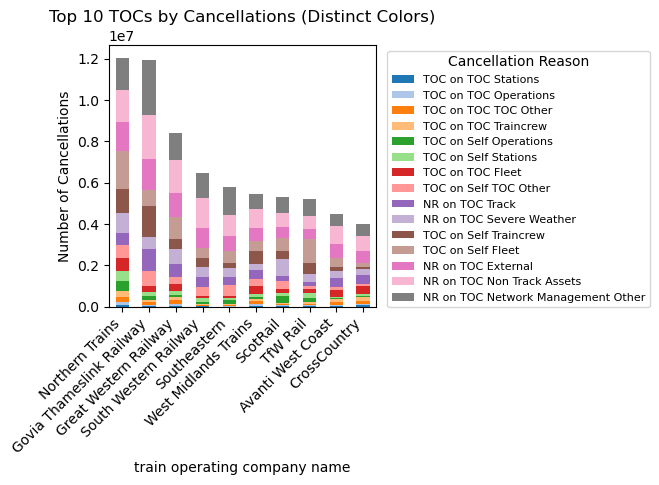

In [20]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Group by operator and sum cancellation reasons across periods
grouped = MariaData.groupby("train operating company name").sum()
cancellation_columns = MariaData.columns[2:]
data = grouped[cancellation_columns]

# Top 10 operators
topN = data.sum(axis=1).sort_values(ascending=False).head(10)
data_top = data.loc[topN.index]

# Sort cancellation reasons so most important appear at top
sorted_columns = data_top.sum().sort_values(ascending=True).index
data_top = data_top[sorted_columns]

# Custom color palette
num_colors = len(data_top.columns)
colors = cm.get_cmap('tab20').colors[:num_colors]  # or tab20b/tab20c

# Plot
plt.figure(figsize=(400, 200))
data_top.plot(kind='bar', stacked=True, color=colors)

plt.xticks(rotation=45, ha='right')
plt.title("Top 10 TOCs by Cancellations (Distinct Colors)")
plt.ylabel("Number of Cancellations")

plt.legend(title="Cancellation Reason",
           bbox_to_anchor=(1.02, 1),
           loc='upper left',
           fontsize=8)

plt.tight_layout()
plt.show()



In [21]:
data_top

,TOC on TOC Stations,TOC on TOC Operations,TOC on TOC TOC Other,TOC on TOC Traincrew,TOC on Self Operations,TOC on Self Stations,TOC on TOC Fleet,TOC on Self TOC Other,NR on TOC Track,NR on TOC Severe Weather,TOC on Self Traincrew,TOC on Self Fleet,NR on TOC External,NR on TOC Non Track Assets,NR on TOC Network Management Other
train operating company name,,,,,,,,,,,,,,,
Northern Trains,"98,413","113,942","232,688","302,773","472,593","483,273","650,106","643,507","570,546","973,561","1,169,221","1,816,013","1,404,351","1,534,072","1,577,730"
Govia Thameslink Railway,"33,898","59,030","142,309","96,046","191,140","189,713","297,650","735,716","1,044,939","560,754","1,510,954","767,037","1,536,366","2,123,263","2,650,887"
Great Western Railway,"56,542","80,130","168,820","142,275","136,581","169,972","363,254","306,606","650,187","696,377","525,237","1,057,773","1,123,889","1,604,451","1,307,949"
South Western Railway,"13,462","29,716","52,261","50,330","59,386","196,094","114,278","420,363","511,722","451,222","433,956","516,974","974,801","1,410,212","1,233,938"
Southeastern,"4,176","24,662","68,928","53,813","161,199","119,933","82,544","542,360","389,660","409,947","275,643","570,546","733,532","990,567","1,347,965"
West Midlands Trains,"53,362","71,422","127,412","143,181","59,370","182,469","343,662","358,497","425,466","297,557","612,218","482,111","669,306","898,335","749,335"
ScotRail,"22,795","38,766","48,952","60,902","346,818","153,357","168,155","379,298","264,029","835,740","392,098","618,455","510,666","694,200","792,010"
TfW Rail,"27,388","34,574","73,228","94,967","166,204","265,226","188,238","175,120","182,016","357,556","541,135","1,154,579","494,139","652,705","813,240"
Avanti West Coast,"39,780","50,316","117,217","147,175","59,866","66,222","326,954","142,741","431,081","338,297","223,778","412,359","680,796","878,838","585,907"


C:\Users\izaan\AppData\Local\Temp\ipykernel_26656\3981744093.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab20').colors[:num_colors]
C:\Users\izaan\AppData\Local\Temp\ipykernel_26656\3981744093.py:36: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


<Figure size 3600x1800 with 0 Axes>

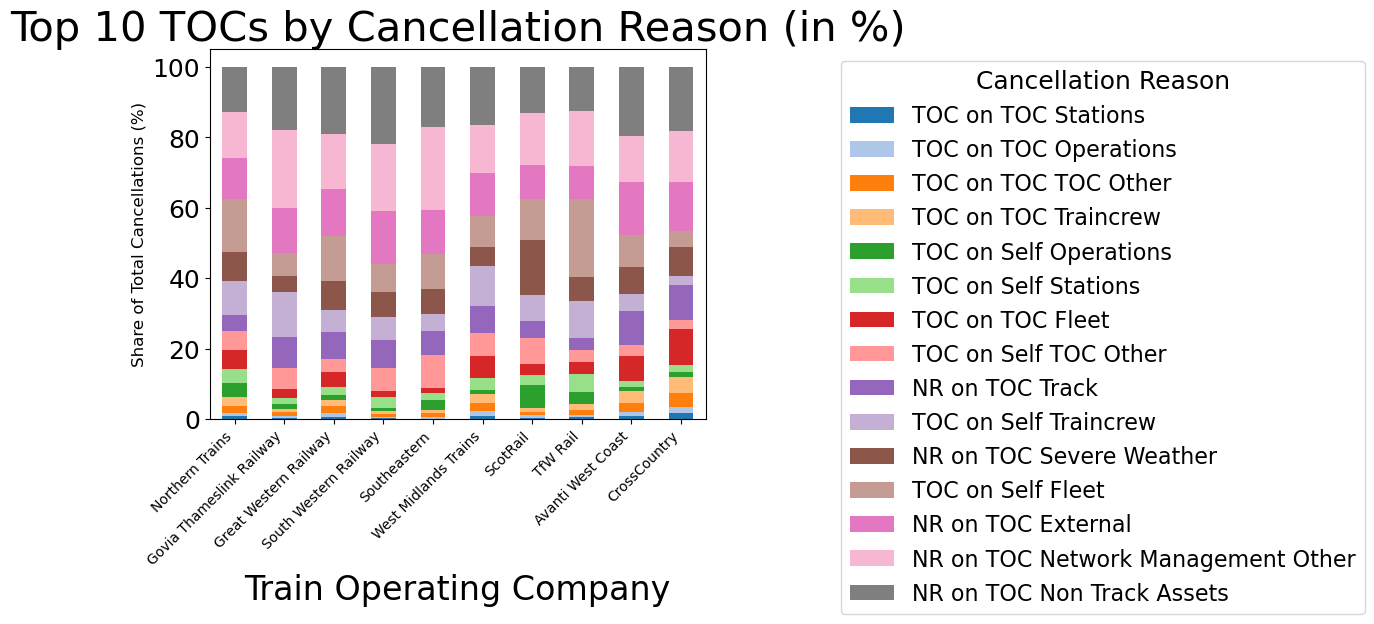

In [30]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm



# Convert raw counts to percentages
data_pct = data_top.div(data_top.sum(axis=1), axis=0) * 100

# Sort columns so the biggest category is drawn last (top of stack)
sorted_columns = data_pct.sum().sort_values(ascending=True).index
data_pct = data_pct[sorted_columns]

# Custom color palette
num_colors = len(data_pct.columns)
colors = cm.get_cmap('tab20').colors[:num_colors]

# Plot percentage stacked bar chart
plt.figure(figsize=(36, 18))
data_pct.plot(kind='bar', stacked=True, color=colors)

plt.xticks(rotation=45, ha='right')
plt.title("Top 10 TOCs by Cancellation Reason (in %)", fontsize=30)
plt.ylabel("Share of Total Cancellations (%)", fontsize=12)
plt.xlabel("Train Operating Company", fontsize=24)
plt.yticks(fontsize=18)

# Shrink legend and move it off to the side
plt.legend(
    title="Cancellation Reason",
    bbox_to_anchor=(1.25, 1),
    loc='upper left',
    fontsize=16,
    title_fontsize=18
)

plt.tight_layout()
plt.show()

In [25]:
data_top.sum().sort_values(ascending=False)

NR on TOC Network Management Other   11,629,937
NR on TOC Non Track Assets           11,512,594
NR on TOC External                    8,687,100
TOC on Self Fleet                     7,576,978
TOC on Self Traincrew                 5,790,164
NR on TOC Severe Weather              5,245,587
NR on TOC Track                       4,863,469
TOC on Self TOC Other                 3,804,003
TOC on TOC Fleet                      2,944,922
TOC on Self Stations                  1,903,146
TOC on Self Operations                1,703,974
TOC on TOC Traincrew                  1,273,430
TOC on TOC TOC Other                  1,196,404
TOC on TOC Operations                   571,339
TOC on TOC Stations                     414,033
dtype: float64

                                       Count  Percent
NR on TOC Network Management Other  11629937       17
NR on TOC Non Track Assets          11512594       17
NR on TOC External                   8687100       13
TOC on Self Fleet                    7576978       11
TOC on Self Traincrew                5790164        8
NR on TOC Severe Weather             5245587        8
NR on TOC Track                      4863469        7
TOC on Self TOC Other                3804003        6
TOC on TOC Fleet                     2944922        4
TOC on Self Stations                 1903146        3
TOC on Self Operations               1703974        2
TOC on TOC Traincrew                 1273430        2
TOC on TOC TOC Other                 1196404        2
TOC on TOC Operations                 571339        1
TOC on TOC Stations                   414033        1


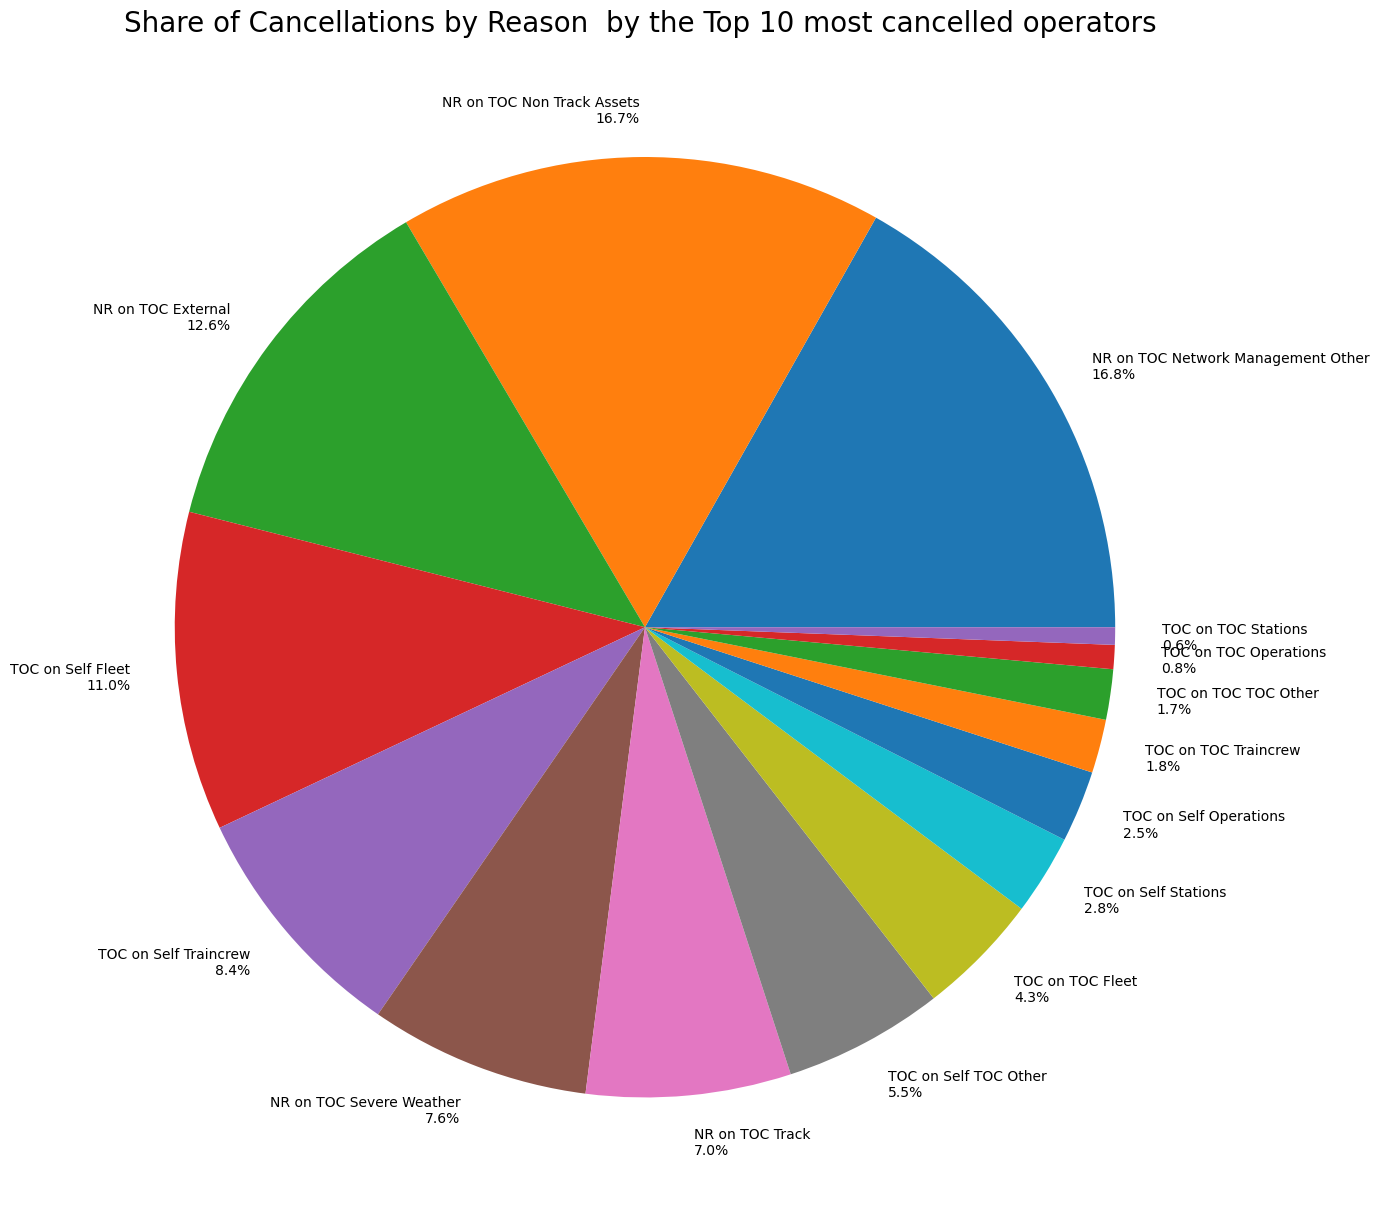

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Raw cancellation totals 
data = {
    "NR on TOC Network Management Other": 11629937,
    "NR on TOC Non Track Assets": 11512594,
    "NR on TOC External": 8687100,
    "TOC on Self Fleet": 7576978,
    "TOC on Self Traincrew": 5790164,
    "NR on TOC Severe Weather": 5245587,
    "NR on TOC Track": 4863469,
    "TOC on Self TOC Other": 3804003,
    "TOC on TOC Fleet": 2944922,
    "TOC on Self Stations": 1903146,
    "TOC on Self Operations": 1703974,
    "TOC on TOC Traincrew": 1273430,
    "TOC on TOC TOC Other": 1196404,
    "TOC on TOC Operations": 571339,
    "TOC on TOC Stations": 414033,
}

df = pd.DataFrame.from_dict(data, orient="index", columns=["Count"])

# Convert to percentage
df["Percent"] = df["Count"] / df["Count"].sum() * 100

# Sort by size (descending)
df = df.sort_values("Percent", ascending=False)

# Display as table
print(df)

# ========== PIE CHART ==========

plt.figure(figsize=(14, 14))

plt.pie(
    df["Percent"],
    labels=[f"{label}\n{value:.1f}%" for label, value in zip(df.index, df["Percent"])],
    autopct=None,   # already formatted in label
    startangle=0,
)

plt.title("Share of Cancellations by Reason  by the Top 10 most cancelled operators ", fontsize=20)
plt.tight_layout()
plt.show()
